# Eksperimen ACNE04: HOG + LBP vs HOG + LBP + HSV (SVM)

**Tujuan:** Menguji apakah penambahan fitur warna HSV meningkatkan klasifikasi tingkat keparahan jerawat pada ACNE04 dibandingkan HOG+LBP saja. Model dilatih **tanpa pretrained model dan tanpa API AI eksternal**.

Metode evaluasi:
1. Gunakan pembagian asli ACNE04: **1.165 train** dan **292 test** (dari kolom `split`).
2. Bagikan data train menjadi **932 train** dan **233 validation** secara stratified (`random_state=42`).
3. Lakukan ekstraksi fitur yang sama, lalu latih dua variasi SVM dan pilih hyperparameter berdasarkan **Macro F1 validation**.
4. Latih ulang masing-masing model terbaik dengan train + validation dan lakukan **testing sekali** untuk membandingkan.

**Catatan:** Karena hasil testing HOG+LBP lama (accuracy ~58%, Macro F1 ~0,51) sudah pernah dilihat, evaluasi lanjutan ini bersifat komparatif/eksploratif. Jangan mengubah konfigurasi berdasarkan skor test untuk menghindari kebocoran pemilihan model.

ACNE04 digunakan untuk penelitian akademik, bukan alat diagnosis medis.

## Cell 1 — Instalasi library

Jalankan pada Google Colab (CPU sudah cukup). Jika runtime restart, jalankan kembali dari atas.

In [ ]:
!pip -q install datasets scikit-image scikit-learn opencv-python-headless pandas matplotlib joblib tqdm

## Cell 2 — Import dan load dataset

Seluruh 1.457 baris berada pada split Hugging Face bernama `train`, tetapi pemisahan resmi **train/test** tersimpan di dalam kolom `split`. Jangan menyamakan keduanya.

In [ ]:
from datasets import load_dataset
from PIL import Image
from skimage.feature import hog, local_binary_pattern
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, mean_absolute_error)
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import cv2
import joblib

NAMA_KELAS = ['Mild', 'Moderate', 'Severe', 'Very Severe']
LABEL_KELAS = [0, 1, 2, 3]
UKURAN_GAMBAR = (128, 128)

data = load_dataset('Layered-Labs/ACNE04', split='train')
print('Jumlah gambar:', len(data))
print('Nama kolom:', data.column_names)

README.md:   0%|          | 0.00/8.60k [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  415MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  410MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  305MB            

data/train-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1457 [00:00<?, ? examples/s]

Jumlah gambar: 1457
Nama kolom: ['image', 'file_name', 'level', 'severity', 'lesion_count_label', 'num_lesions_annotated', 'lesion_boxes', 'split', 'fold_0_split', 'fold_1_split', 'fold_2_split', 'fold_3_split', 'fold_4_split']


## Cell 3 — Pembagian train, validation, dan test (hemat RAM)

Kita **tidak memakai** `.filter()` pada dataset gambar. Ambil metadata `split` dan `level` saja, kemudian pilih indeks menggunakan `.select()` ketika dibutuhkan. Model tidak boleh mengakses label test untuk training atau pemilihan parameter.

In [ ]:
metadata = data.select_columns(['split', 'level'])
splits = np.asarray(metadata['split'])
levels = np.asarray(metadata['level'], dtype=int)

idx_train_asli = np.where(splits == 'train')[0]
idx_test = np.where(splits == 'test')[0]

idx_train, idx_val = train_test_split(
    idx_train_asli,
    test_size=0.2,
    random_state=42,
    stratify=levels[idx_train_asli]
)

print('Training   :', len(idx_train))
print('Validation :', len(idx_val))
print('Testing    :', len(idx_test))

assert len(idx_train) == 932 and len(idx_val) == 233 and len(idx_test) == 292
assert not (set(idx_train) & set(idx_val))
assert not (set(idx_train) & set(idx_test))
assert not (set(idx_val) & set(idx_test))

print('\nDistribusi label:')
for nama, idx in [('Train', idx_train), ('Validation', idx_val), ('Test', idx_test)]:
    hitung = np.bincount(levels[idx], minlength=4)
    print(nama, dict(zip(NAMA_KELAS, hitung.tolist())))

Training   : 932
Validation : 233
Testing    : 292

Distribusi label:
Train {'Mild': 328, 'Moderate': 405, 'Severe': 117, 'Very Severe': 82}
Validation {'Mild': 82, 'Moderate': 101, 'Severe': 29, 'Very Severe': 21}
Test {'Mild': 103, 'Moderate': 127, 'Severe': 36, 'Very Severe': 26}


## Cell 4 — Fungsi ekstraksi HOG, LBP, dan HSV

- **HOG:** arah tepi/bentuk dalam gambar grayscale (1.764 angka).
- **LBP:** histogram tekstur grayscale pada kisi 4 × 4 (160 angka).
- **HSV:** histogram warna Hue, Saturation, dan Value pada kisi 2 × 2 (112 angka).

Histogram HSV setiap kanal pada setiap area dinormalisasi supaya perbedaan ukuran histogram tidak hanya berasal dari jumlah piksel. Warna diperoleh dari gambar RGB; **jangan** mengambil HSV dari grayscale.

In [ ]:
def ekstrak_fitur(gambar):
    # 1) Resize dan siapkan RGB serta grayscale
    gambar = gambar.convert('RGB').resize(UKURAN_GAMBAR, Image.Resampling.BILINEAR)
    rgb = np.asarray(gambar, dtype=np.uint8)
    gray = np.asarray(gambar.convert('L'), dtype=np.uint8)

    # 2) HOG: 1.764 fitur
    fitur_hog = hog(
        gray,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm='L2-Hys',
        feature_vector=True
    ).astype(np.float32)

    # 3) LBP: 4 x 4 bagian, masing-masing histogram 10 nilai
    peta_lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    fitur_lbp = []

    for baris in range(0, 128, 32):
        for kolom in range(0, 128, 32):
            bagian = peta_lbp[baris:baris+32, kolom:kolom+32]
            hist, _ = np.histogram(bagian.ravel(), bins=np.arange(0, 11))
            hist = hist.astype(np.float32)
            hist = hist / (hist.sum() + 1e-8)
            fitur_lbp.extend(hist)

    # 4) HSV: 2 x 2 bagian, histogram warna per kanal
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    fitur_hsv = []

    for baris in range(0, 128, 64):
        for kolom in range(0, 128, 64):
            bagian = hsv[baris:baris+64, kolom:kolom+64]

            for kanal, bins, nilai_maks in [(0, 12, 180), (1, 8, 256), (2, 8, 256)]:
                hist, _ = np.histogram(
                    bagian[:, :, kanal].ravel(),
                    bins=bins,
                    range=(0, nilai_maks)
                )
                hist = hist.astype(np.float32)
                hist = hist / (hist.sum() + 1e-8)
                fitur_hsv.extend(hist)

    # 5) Pisahkan baseline dengan fitur warna baru
    fitur_baseline = np.concatenate([fitur_hog, np.asarray(fitur_lbp, dtype=np.float32)])
    fitur_hsv = np.asarray(fitur_hsv, dtype=np.float32)
    return fitur_baseline, fitur_hsv

# Pemeriksaan pada satu gambar
baseline_contoh, hsv_contoh = ekstrak_fitur(data[int(idx_train[0])]['image'])
print('HOG + LBP       :', baseline_contoh.shape)
print('HSV             :', hsv_contoh.shape)
print('HOG + LBP + HSV :', len(baseline_contoh) + len(hsv_contoh))

HOG + LBP       : (1924,)
HSV             : (112,)
HOG + LBP + HSV : 2036


## Cell 5 — Visualisasi RGB, HOG, LBP, HSV (opsional)

Tidak memengaruhi training. Berguna untuk memahami hasil pemrosesan citra.

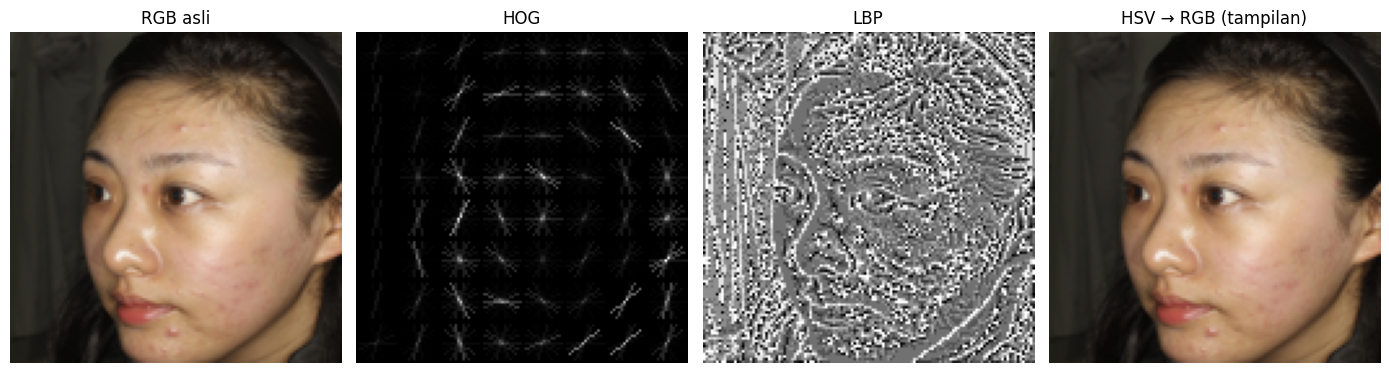

In [ ]:
contoh_gambar = data[int(idx_train[0])]['image'].convert('RGB').resize(UKURAN_GAMBAR)
rgb = np.asarray(contoh_gambar)
gray = np.asarray(contoh_gambar.convert('L'))
_, gambar_hog = hog(gray, orientations=9, pixels_per_cell=(16, 16),
                    cells_per_block=(2, 2), visualize=True)
gambar_lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
gambar_hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(rgb)
axes[0].set_title('RGB asli')
axes[1].imshow(gambar_hog, cmap='gray')
axes[1].set_title('HOG')
axes[2].imshow(gambar_lbp, cmap='gray')
axes[2].set_title('LBP')
axes[3].imshow(cv2.cvtColor(gambar_hsv, cv2.COLOR_HSV2RGB))
axes[3].set_title('HSV → RGB (tampilan)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Cell 6 — Ekstraksi fitur training dan validation (hemat RAM)

Gambar didekode **satu per satu**, dan yang disimpan hanya vektor fiturnya. Tidak membuat array besar berisi seluruh gambar. Ekstraksi HOG/LBP/HSV dilakukan sekali saja per gambar.

In [ ]:
def ekstrak_dataset(data, daftar_indeks, nama='Data'):
    semua_baseline = []
    semua_hsv = []

    for indeks in tqdm(daftar_indeks, desc=nama):
        gambar = data[int(indeks)]['image']
        fitur_baseline, fitur_hsv = ekstrak_fitur(gambar)
        semua_baseline.append(fitur_baseline)
        semua_hsv.append(fitur_hsv)

    return (np.asarray(semua_baseline, dtype=np.float32),
            np.asarray(semua_hsv, dtype=np.float32))

X_train_base, X_train_warna = ekstrak_dataset(data, idx_train, 'Training')
X_val_base, X_val_warna = ekstrak_dataset(data, idx_val, 'Validation')

y_train = levels[idx_train]
y_val = levels[idx_val]

# Gabungkan HSV dengan HOG+LBP untuk versi baru
X_train_hsv = np.hstack([X_train_base, X_train_warna])
X_val_hsv = np.hstack([X_val_base, X_val_warna])

print('Model A: train', X_train_base.shape, 'val', X_val_base.shape)
print('Model B: train', X_train_hsv.shape, 'val', X_val_hsv.shape)

Training:   0%|          | 0/932 [00:00<?, ?it/s]

Validation:   0%|          | 0/233 [00:00<?, ?it/s]

Model A: train (932, 1924) val (233, 1924)
Model B: train (932, 2036) val (233, 2036)


## Cell 7 — Pilih hyperparameter hanya dari validation

Setiap model mendapat daftar kombinasi parameter yang sama: Linear (C = 0,1; 1; 10) dan RBF (C = 1; 10 serta gamma = `scale`; 0,0001; 0,001).

`StandardScaler` ditempatkan di dalam pipeline agar **hanya di-fit pada training**; validation tidak dipakai untuk menghitung rata-rata atau simpangan baku scaling. `class_weight='balanced'` mengurangi pengaruh ketidakseimbangan label. Pemilihan berdasarkan **Macro F1 validation**, bukan test.

In [ ]:
konfigurasi = []
for C in [0.1, 1, 10]:
    konfigurasi.append({'kernel': 'linear', 'C': C, 'gamma': 'scale'})
for C in [1, 10]:
    for gamma in ['scale', 0.0001, 0.001]:
        konfigurasi.append({'kernel': 'rbf', 'C': C, 'gamma': gamma})

hasil_validasi = []
parameter_terbaik = {}

data_model = {
    'HOG + LBP': (X_train_base, X_val_base),
    'HOG + LBP + HSV': (X_train_hsv, X_val_hsv)
}

for nama_model, (Xtr, Xva) in data_model.items():
    skor_terbaik = -1
    print('\nMencoba:', nama_model)

    for param in tqdm(konfigurasi, desc=nama_model):
        model = make_pipeline(
            StandardScaler(),
            SVC(kernel=param['kernel'], C=param['C'],
                gamma=param['gamma'], class_weight='balanced')
        )
        model.fit(Xtr, y_train)
        prediksi_val = model.predict(Xva)

        macro_f1 = f1_score(y_val, prediksi_val, labels=LABEL_KELAS,
                            average='macro', zero_division=0)
        akurasi = accuracy_score(y_val, prediksi_val)
        recall_per_kelas = recall_score(y_val, prediksi_val,
                                       labels=LABEL_KELAS, average=None,
                                       zero_division=0)

        hasil_validasi.append({
            'Model': nama_model,
            'Kernel': param['kernel'],
            'C': param['C'],
            'gamma': str(param['gamma']),
            'Accuracy_val': akurasi,
            'Macro_F1_val': macro_f1,
            'Recall_Severe_val': recall_per_kelas[2]
        })

        if macro_f1 > skor_terbaik:
            skor_terbaik = macro_f1
            parameter_terbaik[nama_model] = param.copy()

hasil_df = pd.DataFrame(hasil_validasi)
for nama_model in data_model:
    print('\n=== Hasil validation:', nama_model, '===')
    display(hasil_df[hasil_df['Model'] == nama_model]
            .sort_values('Macro_F1_val', ascending=False)
            .head(5).round(4))
    print('Parameter terbaik:', parameter_terbaik[nama_model])

# Simpan tabel eksperimen validation
hasil_df.to_csv('/content/hasil_validasi_hog_lbp_hsv.csv', index=False)


Mencoba: HOG + LBP


HOG + LBP:   0%|          | 0/9 [00:00<?, ?it/s]


Mencoba: HOG + LBP + HSV


HOG + LBP + HSV:   0%|          | 0/9 [00:00<?, ?it/s]


=== Hasil validation: HOG + LBP ===


,Model,Kernel,C,gamma,Accuracy_val,Macro_F1_val,Recall_Severe_val
0,HOG + LBP,linear,0.1,scale,0.5021,0.4911,0.2759
1,HOG + LBP,linear,1.0,scale,0.4979,0.4883,0.2759
2,HOG + LBP,linear,10.0,scale,0.4979,0.4883,0.2759
6,HOG + LBP,rbf,10.0,scale,0.5579,0.4853,0.0690
7,HOG + LBP,rbf,10.0,0.0001,0.4807,0.4574,0.2069


Parameter terbaik: {'kernel': 'linear', 'C': 0.1, 'gamma': 'scale'}

=== Hasil validation: HOG + LBP + HSV ===


,Model,Kernel,C,gamma,Accuracy_val,Macro_F1_val,Recall_Severe_val
15,HOG + LBP + HSV,rbf,10.0,scale,0.5665,0.4971,0.1034
9,HOG + LBP + HSV,linear,0.1,scale,0.4979,0.4732,0.2069
10,HOG + LBP + HSV,linear,1.0,scale,0.4979,0.4732,0.2069
11,HOG + LBP + HSV,linear,10.0,scale,0.4979,0.4732,0.2069
16,HOG + LBP + HSV,rbf,10.0,0.0001,0.4936,0.4605,0.2069


Parameter terbaik: {'kernel': 'rbf', 'C': 10, 'gamma': 'scale'}


## Cell 8 — Lihat laporan validation terbaik

Bagian ini hanya melihat data validation. Bisa membantu mengetahui apakah penambahan warna meningkatkan kelas **Severe** sebelum testing.

In [ ]:
for nama_model, (Xtr, Xva) in data_model.items():
    param = parameter_terbaik[nama_model]
    model_val = make_pipeline(
        StandardScaler(),
        SVC(kernel=param['kernel'], C=param['C'],
            gamma=param['gamma'], class_weight='balanced')
    )
    model_val.fit(Xtr, y_train)
    pred = model_val.predict(Xva)

    print('\n=== Classification Report VALIDATION:', nama_model, '===')
    print(classification_report(y_val, pred, labels=LABEL_KELAS,
                                target_names=NAMA_KELAS, zero_division=0))


=== Classification Report VALIDATION: HOG + LBP ===
              precision    recall  f1-score   support

        Mild       0.47      0.54      0.50        82
    Moderate       0.53      0.51      0.52       101
      Severe       0.38      0.28      0.32        29
 Very Severe       0.62      0.62      0.62        21

    accuracy                           0.50       233
   macro avg       0.50      0.49      0.49       233
weighted avg       0.50      0.50      0.50       233


=== Classification Report VALIDATION: HOG + LBP + HSV ===
              precision    recall  f1-score   support

        Mild       0.65      0.50      0.57        82
    Moderate       0.53      0.75      0.62       101
      Severe       0.30      0.10      0.15        29
 Very Severe       0.75      0.57      0.65        21

    accuracy                           0.57       233
   macro avg       0.56      0.48      0.50       233
weighted avg       0.56      0.57      0.55       233



## Cell 9 — Ekstraksi fitur testing (setelah pemilihan model)

Fitur testing dihitung **setelah parameter final dipilih**. Evaluasi test jangan dipakai untuk mengulangi hyperparameter search.

In [ ]:
X_test_base, X_test_warna = ekstrak_dataset(data, idx_test, 'Testing')
X_test_hsv = np.hstack([X_test_base, X_test_warna])
y_test = levels[idx_test]

print('X_test_base:', X_test_base.shape)
print('X_test_hsv :', X_test_hsv.shape)
print('y_test     :', y_test.shape)

Testing:   0%|          | 0/292 [00:00<?, ?it/s]

X_test_base: (292, 1924)
X_test_hsv : (292, 2036)
y_test     : (292,)


## Cell 10 — Training final dengan train + validation; evaluasi test

Setiap model dibuat ulang menggunakan hyperparameter terbaik dari validation lalu dilatih pada **1.165 gambar** (train + validation). Terakhir, kedua model diuji pada 292 gambar testing yang sama.

In [ ]:
X_full_base = np.vstack([X_train_base, X_val_base])
X_full_hsv = np.vstack([X_train_hsv, X_val_hsv])
y_full = np.concatenate([y_train, y_val])

matriks_final = {
    'HOG + LBP': (X_full_base, X_test_base),
    'HOG + LBP + HSV': (X_full_hsv, X_test_hsv)
}

model_final = {}
prediksi_test = {}
ringkasan_test = []

for nama_model, (X_full, Xtest) in matriks_final.items():
    param = parameter_terbaik[nama_model]

    model = make_pipeline(
        StandardScaler(),
        SVC(kernel=param['kernel'], C=param['C'],
            gamma=param['gamma'], class_weight='balanced')
    )
    model.fit(X_full, y_full)
    pred = model.predict(Xtest)
    recall = recall_score(y_test, pred, labels=LABEL_KELAS,
                          average=None, zero_division=0)

    model_final[nama_model] = model
    prediksi_test[nama_model] = pred
    ringkasan_test.append({
        'Model': nama_model,
        'Accuracy': accuracy_score(y_test, pred),
        'Macro_F1': f1_score(y_test, pred, labels=LABEL_KELAS,
                             average='macro', zero_division=0),
        'Recall_Severe': recall[2],
        'Recall_Very_Severe': recall[3],
        'MAE_severity': mean_absolute_error(y_test, pred)
    })

    print('\n=== TEST:', nama_model, '===')
    print(classification_report(y_test, pred, labels=LABEL_KELAS,
                                target_names=NAMA_KELAS, zero_division=0))

perbandingan_test = pd.DataFrame(ringkasan_test)
display(perbandingan_test.round(4))
perbandingan_test.to_csv('/content/perbandingan_test_hog_lbp_vs_hsv.csv', index=False)


=== TEST: HOG + LBP ===
              precision    recall  f1-score   support

        Mild       0.53      0.50      0.52       103
    Moderate       0.49      0.53      0.51       127
      Severe       0.28      0.22      0.25        36
 Very Severe       0.39      0.42      0.41        26

    accuracy                           0.47       292
   macro avg       0.42      0.42      0.42       292
weighted avg       0.47      0.47      0.47       292


=== TEST: HOG + LBP + HSV ===
              precision    recall  f1-score   support

        Mild       0.68      0.52      0.59       103
    Moderate       0.57      0.76      0.65       127
      Severe       0.36      0.14      0.20        36
 Very Severe       0.55      0.62      0.58        26

    accuracy                           0.59       292
   macro avg       0.54      0.51      0.51       292
weighted avg       0.58      0.59      0.57       292



,Model,Accuracy,Macro_F1,Recall_Severe,Recall_Very_Severe,MAE_severity
0,HOG + LBP,0.4726,0.4196,0.2222,0.4231,0.6301
1,HOG + LBP + HSV,0.5856,0.5052,0.1389,0.6154,0.4829


## Cell 11 — Confusion Matrix kedua model

**Perhatikan baris Severe**: apakah model baru berhasil mengenali lebih banyak gambar Severe atau justru memperburuk kelas lain?

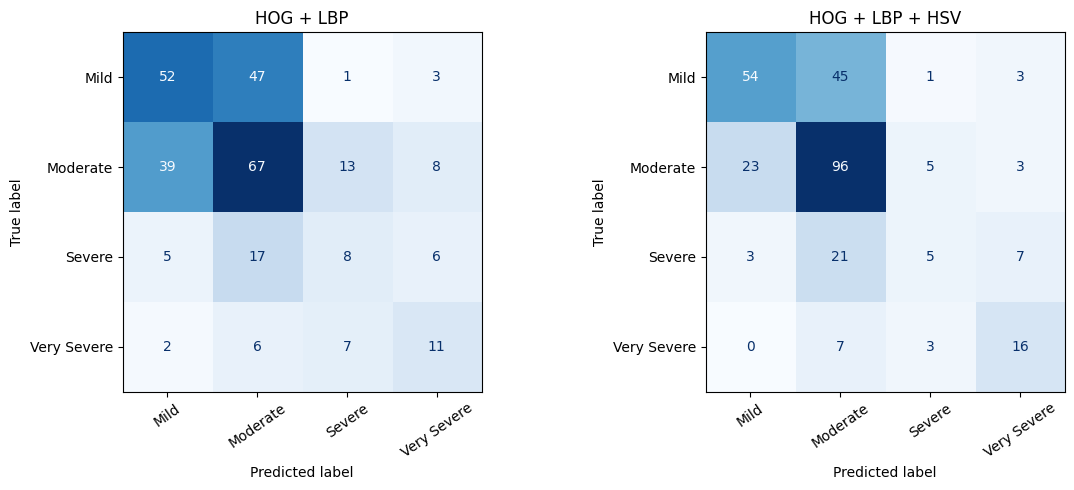

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, nama_model in zip(axes, ['HOG + LBP', 'HOG + LBP + HSV']):
    cm = confusion_matrix(y_test, prediksi_test[nama_model], labels=LABEL_KELAS)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=NAMA_KELAS)
    disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d', xticks_rotation=35)
    ax.set_title(nama_model)

plt.tight_layout()
plt.show()

## Cell 12 — Simpan model dan konfigurasi

Model `.joblib` menyimpan `StandardScaler` + `SVC`. Ekstraksi HOG/LBP/HSV dilakukan **sebelum** pipeline, sehingga fungsi `ekstrak_fitur()` dalam notebook juga wajib dipertahankan untuk prediksi gambar baru.

In [ ]:
for nama_model, nama_file in [
    ('HOG + LBP', 'model_hog_lbp_svm.joblib'),
    ('HOG + LBP + HSV', 'model_hog_lbp_hsv_svm.joblib')
]:
    joblib.dump({
        'model': model_final[nama_model],
        'metode': nama_model,
        'ukuran_gambar': UKURAN_GAMBAR,
        'nama_kelas': NAMA_KELAS,
        'parameter': parameter_terbaik[nama_model]
    }, '/content/' + nama_file)
    print('Tersimpan:', nama_file)

# Untuk mengunduh salah satu model di Colab:
# from google.colab import files
# files.download('/content/model_hog_lbp_hsv_svm.joblib')

## Cell 13 — Coba prediksi satu gambar baru

Unggah foto menggunakan Colab. Hasilnya merupakan klasifikasi visual, **bukan diagnosis medis**.

In [ ]:
from google.colab import files
import io

unggahan = files.upload()
nama_file = next(iter(unggahan))
gambar_baru = Image.open(io.BytesIO(unggahan[nama_file]))

base, warna = ekstrak_fitur(gambar_baru)
fitur_baru = np.concatenate([base, warna]).reshape(1, -1)

label_prediksi = int(model_final['HOG + LBP + HSV'].predict(fitur_baru)[0])
plt.figure(figsize=(5, 5))
plt.imshow(gambar_baru)
plt.title('Prediksi HSV + SVM: ' + NAMA_KELAS[label_prediksi])
plt.axis('off')
plt.show()

## Cara membaca dan melaporkan hasil

- **Macro F1 validation** menentukan parameter, bukan skor testing.
- **Accuracy test** menunjukkan proporsi prediksi benar; bandingkan dengan 58% baseline lama **hanya sebagai konteks**, karena prosedur pemilihan parameternya kini mungkin berbeda.
- **Recall Severe** penting karena model lama hanya mencapai sekitar 17% pada kelas ini.
- **Macro F1, recall Severe, MAE severity, confusion matrix** perlu dilaporkan bersama-sama. HSV bisa membantu sebagian kelas tetapi menurunkan kelas lain.
- Jika ingin tuning resolusi, bin histogram, `C`, atau `gamma` lagi, lakukan hanya berdasarkan **validation**/cross-validation data training. Jangan berulang-ulang memilih setting berdasarkan test.
- Model SVM `.joblib` tidak otomatis menjadi TFLite. Integrasi offline di Flutter perlu implementasi preprocessing HOG, LBP, HSV, scaling dan inferensi SVM yang identik.

**Sumber:** [ACNE04](https://huggingface.co/datasets/Layered-Labs/ACNE04), [HOG dan LBP scikit-image](https://scikit-image.org/docs/stable/api/skimage.feature.html).